In [1]:
import pandas as pd
import plotly.graph_objects as go

from plotly.subplots import make_subplots

In [2]:
df2 = pd.DataFrame({
    "Month": [
        "Jan","Jan","Feb","Feb","Mar","Mar",
        "Apr","Apr","May","May","Jun","Jun",
        "Jul","Jul","Aug","Aug","Sep","Sep"
    ],

    "Room_Type": [
        "Standard","Deluxe","Standard","Suite","Deluxe","Suite",
        "Standard","Deluxe","Suite","Standard","Deluxe","Suite",
        "Standard","Deluxe","Suite","Standard","Deluxe","Suite"
    ],

    "Bookings": [
        120,75,135,48,160,62,
        180,92,70,195,110,82,
        210,125,95,225,140,105
    ],

    "Occupancy_Percent": [
        62,74,68,81,72,84,
        76,79,86,82,85,89,
        88,91,93,90,94,95
    ],

    "Revenue": [
        360000,375000,405000,336000,480000,434000,
        540000,460000,490000,585000,550000,574000,
        630000,625000,665000,675000,700000,735000
    ],

    "Food_Revenue": [
        85000,62000,92000,58000,105000,72000,
        118000,78000,125000,130000,98000,135000,
        145000,112000,155000,160000,125000,172000
    ],

    "Customers": [
        210,140,235,95,280,120,
        310,165,135,340,195,155,
        380,220,175,410,245,190
    ],

    "Rating": [
        4.1,4.3,4.2,4.5,4.0,4.6,
        4.2,4.4,4.7,4.3,4.5,4.6,
        4.4,4.7,4.8,4.5,4.8,4.9
    ],

    "Booking_Source": [
        "Website","Booking.com","Website","Agoda","Booking.com","Website",
        "Website","Agoda","Booking.com","Website","Booking.com","Agoda",
        "Website","Booking.com","Website","Agoda","Booking.com","Website"
    ]
})

In [5]:
month_wise_avg_food_revenue = df2.groupby("Month")["Food_Revenue"].mean()
month_wise_avg_food_revenue

Month
Apr     98000.0
Aug    157500.0
Feb     75000.0
Jan     73500.0
Jul    128500.0
Jun    116500.0
Mar     88500.0
May    127500.0
Sep    148500.0
Name: Food_Revenue, dtype: float64

In [6]:
room_total_revenue = df2.groupby("Room_Type")["Revenue"].sum()
room_total_revenue

Room_Type
Deluxe      3190000
Standard    3195000
Suite       3234000
Name: Revenue, dtype: int64

In [7]:
room_total_booking = df2.groupby("Room_Type")["Bookings"].sum()
room_total_booking

Room_Type
Deluxe       702
Standard    1065
Suite        462
Name: Bookings, dtype: int64

In [8]:
room_total_customer = df2.groupby("Room_Type")["Customers"].sum()
room_total_customer

Room_Type
Deluxe      1245
Standard    1885
Suite        870
Name: Customers, dtype: int64

In [9]:
room_occupacy = df2.groupby("Room_Type")["Occupancy_Percent"].mean()
room_occupacy

Room_Type
Deluxe      82.500000
Standard    77.666667
Suite       88.000000
Name: Occupancy_Percent, dtype: float64

In [10]:
room_avg_rating = df2.groupby("Room_Type")["Rating"].mean()
room_avg_rating

Room_Type
Deluxe      4.450000
Standard    4.283333
Suite       4.683333
Name: Rating, dtype: float64

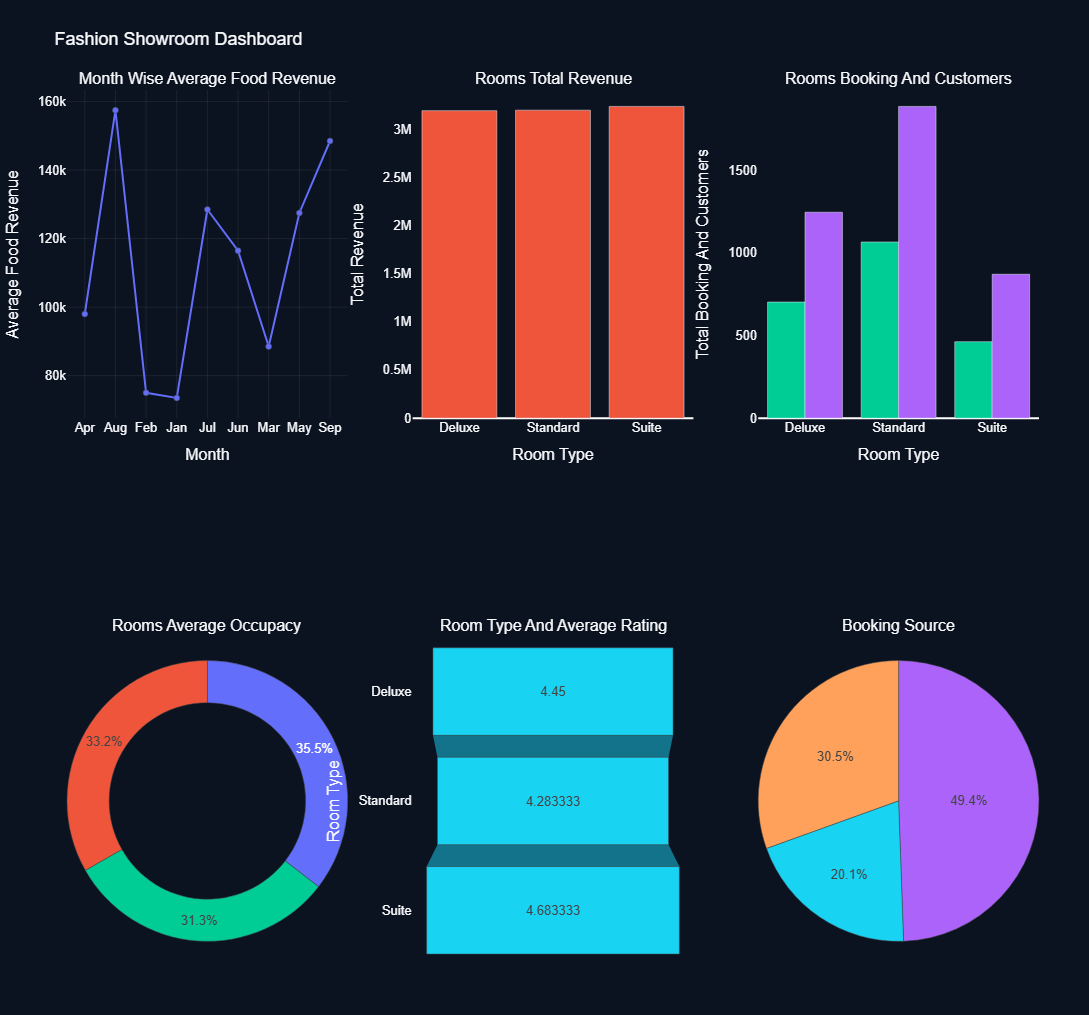

In [15]:
fig = make_subplots(

    rows=2,
    cols=3,

    subplot_titles=(
        "Month Wise Average Food Revenue",
        "Rooms Total Revenue",
        "Rooms Booking And Customers",
        "Rooms Average Occupacy",
        "Room Type And Average Rating",
        "Booking Source"
    ),

    specs=[
        [{"type":"xy"},{"type":"xy"},{"type":"xy"}],
        [{"type":"domain"},{"type":"xy"},{"type":"domain"}]
    ]
)


fig.add_trace(
    go.Scatter(
        x=month_wise_avg_food_revenue.index,
        y=month_wise_avg_food_revenue.values,
        name="Average Food Revenue"
    ),
    row=1,
    col=1
)



fig.add_trace(
    go.Bar(
        x=room_total_revenue.index,
        y=room_total_revenue.values,
        name="Total Revenue"
    ),
    row=1,
    col=2
)



fig.add_trace(
    go.Bar(
        x=room_total_booking.index,
        y=room_total_booking.values,
        name="Room Total Booking"
    ),
    row=1,
    col=3
)



fig.add_trace(
    go.Bar(
        x=room_total_customer.index,
        y=room_total_customer.values,
        name="Room Total Customers"
    ),
    row=1,
    col=3
    
)



fig.add_trace(
    go.Pie(
        labels=room_occupacy.index,
        values=room_occupacy.values,
        name="Room Avg Accupacy",
        hole=0.7
    ),
    row=2,
    col=1
)



fig.add_trace(
    go.Funnel(
        y=room_avg_rating.index,
        x=room_avg_rating.values,
        name="Room Average Rating"
    ),
    row=2,
    col=2
)


fig.add_trace(
    go.Pie(
        labels=df2["Booking_Source"],
        values=df2["Bookings"]
    ),
    row=2,
    col=3
)




fig.update_traces(

    marker=dict(
        line=dict(
            width=0.5
        )
    )
)



fig.update_xaxes(
    title="Month",
    showgrid=True,
    gridwidth=0.5,
    gridcolor="rgba(255,255,255,0.15)",

    row=1,
    col=1
)


fig.update_xaxes(
    title="Room Type",
    showgrid=False,

    row=1,
    col=2
)


fig.update_xaxes(
    title="Room Type",
    showgrid=False,

    row=1,
    col=3
)


fig.update_xaxes(
    title="Room Type",
    showgrid=False,

    row=2,
    col=2
)



fig.update_yaxes(
    title="Average Food Revenue",
    showgrid=True,
    gridwidth=0.5,
    gridcolor="rgba(255,255,255,0.15)",

    row=1,
    col=1
)


fig.update_yaxes(
    title="Total Revenue",
    showgrid=False,
    row=1,
    col=2
)


fig.update_yaxes(
    title="Total Booking And Customers",
    showgrid=False,
    row=1,
    col=3
)


fig.update_yaxes(
    title="Room Type",
    showgrid=False,
    row=2,
    col=2
)




fig.update_layout(

    title="Fashion Showroom Dashboard",

    width=1300,
    height=1000,

    paper_bgcolor="#0B1220",

    plot_bgcolor="#0B1220",

    font=dict(
        family="Arial",
        size=13,
        color="#F8FAFC"
    ),

    margin=dict(
        l=50,
        r=50,
        t=90,
        b=5
    ),

    showlegend=False
    
)

In [3]:
df2

,Month,Room_Type,Bookings,Occupancy_Percent,Revenue,Food_Revenue,Customers,Rating,Booking_Source
0,Jan,Standard,120,62,360000,85000,210,4.1,Website
1,Jan,Deluxe,75,74,375000,62000,140,4.3,Booking.com
2,Feb,Standard,135,68,405000,92000,235,4.2,Website
3,Feb,Suite,48,81,336000,58000,95,4.5,Agoda
4,Mar,Deluxe,160,72,480000,105000,280,4.0,Booking.com
5,Mar,Suite,62,84,434000,72000,120,4.6,Website
6,Apr,Standard,180,76,540000,118000,310,4.2,Website
7,Apr,Deluxe,92,79,460000,78000,165,4.4,Agoda
8,May,Suite,70,86,490000,125000,135,4.7,Booking.com
9,May,Standard,195,82,585000,130000,340,4.3,Website
